In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [3]:
df = pd.read_csv(r"C:\Users\sreya\Desktop\Fraud Detection Assignments\Fraud Detection Dataset.csv")
print(df.shape)
df.head()

(51000, 12)


,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent
0,T1,4174,1292.76,ATM Withdrawal,16.0,Tablet,San Francisco,0,119,13,Debit Card,0
1,T2,4507,1554.58,ATM Withdrawal,13.0,Mobile,New York,4,79,3,Credit Card,0
2,T3,1860,2395.02,ATM Withdrawal,NaN,Mobile,NaN,3,115,9,NaN,0
3,T4,2294,100.10,Bill Payment,15.0,Desktop,Chicago,4,3,4,UPI,0
4,T5,2130,1490.50,POS Payment,19.0,Mobile,San Francisco,2,57,7,Credit Card,0


In [4]:
df.columns.tolist()
list(df)

['Transaction_ID',
 'User_ID',
 'Transaction_Amount',
 'Transaction_Type',
 'Time_of_Transaction',
 'Device_Used',
 'Location',
 'Previous_Fraudulent_Transactions',
 'Account_Age',
 'Number_of_Transactions_Last_24H',
 'Payment_Method',
 'Fraudulent']

In [5]:
df=df.dropna()

In [6]:
missing_percent = df.isnull().mean()*100

print(missing_percent)

Transaction_ID                      0.0
User_ID                             0.0
Transaction_Amount                  0.0
Transaction_Type                    0.0
Time_of_Transaction                 0.0
Device_Used                         0.0
Location                            0.0
Previous_Fraudulent_Transactions    0.0
Account_Age                         0.0
Number_of_Transactions_Last_24H     0.0
Payment_Method                      0.0
Fraudulent                          0.0
dtype: float64


In [7]:
duplicates = df.duplicated().sum()

print("Duplicate Records:", duplicates)

Duplicate Records: 688


## Task1: Column wise Duplicate count

In [8]:
dup_count = df.apply(lambda col: col.duplicated().sum())

unique_count = df.nunique()

task1 = pd.DataFrame({
    "Duplicate_Count": dup_count,
    "Unique_Count": unique_count
})

print(task1)

                                  Duplicate_Count  Unique_Count
Transaction_ID                                787         38796
User_ID                                     35583          4000
Transaction_Amount                           2667         36916
Transaction_Type                            39578             5
Time_of_Transaction                         39559            24
Device_Used                                 39579             4
Location                                    39575             8
Previous_Fraudulent_Transactions            39578             5
Account_Age                                 39464           119
Number_of_Transactions_Last_24H             39569            14
Payment_Method                              39578             5
Fraudulent                                  39581             2


##### Task 1: Observations

- The dataset has **39,583 rows** after removing missing values.
- **Duplicate_Count** shows how many times a value is repeated within a column, and **Unique_Count** shows how many distinct values the column has. Together they add up to the total number of rows.
- Categorical columns such as `Transaction_Type`, `Device_Used`, `Payment_Method` and `Fraudulent` have very high duplicate counts. This is expected, because they contain only a few categories.
- `Transaction_ID` should be unique for every transaction, but it has **787 repeated values**. This points to duplicate records in the data.
- Of these, **688 rows are exact duplicates** across all columns (from `df.duplicated().sum()`). The remaining 99 share a Transaction ID but differ in at least one other column.
- `User_ID` has 4,000 unique values, which means each user has made multiple transactions.

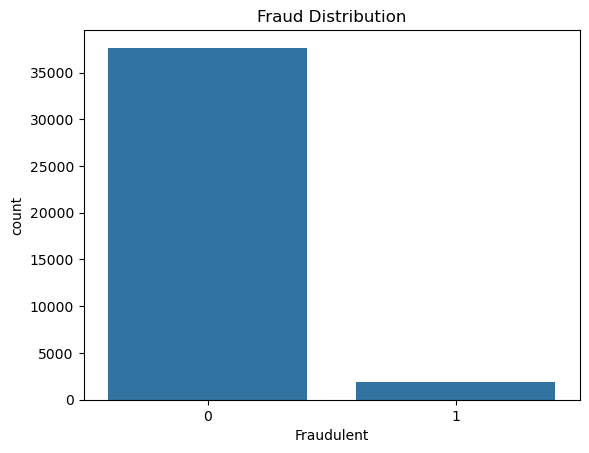

In [9]:
sns.countplot(x="Fraudulent", data=df)

plt.title("Fraud Distribution")

plt.show()

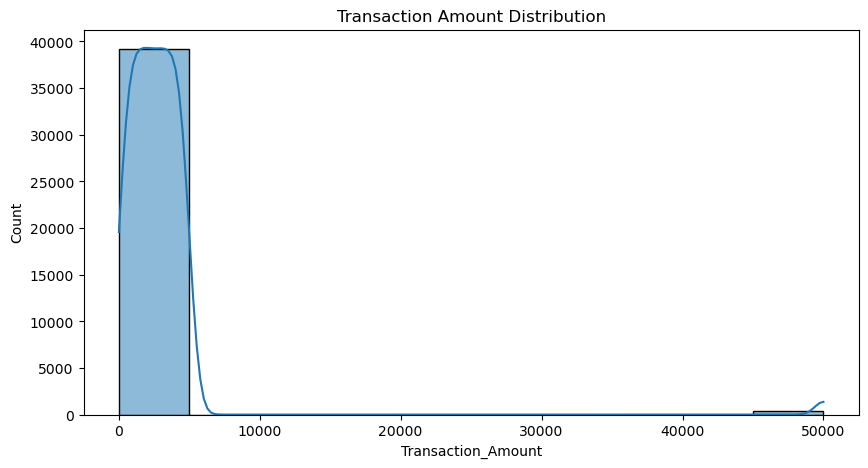

In [10]:
plt.figure(figsize=(10,5))

sns.histplot(
    df["Transaction_Amount"],
    bins=10,
    kde=True
)

plt.title("Transaction Amount Distribution")

plt.show()

## Task2(a): Cluster for Payment_Method v/s Fraudulent

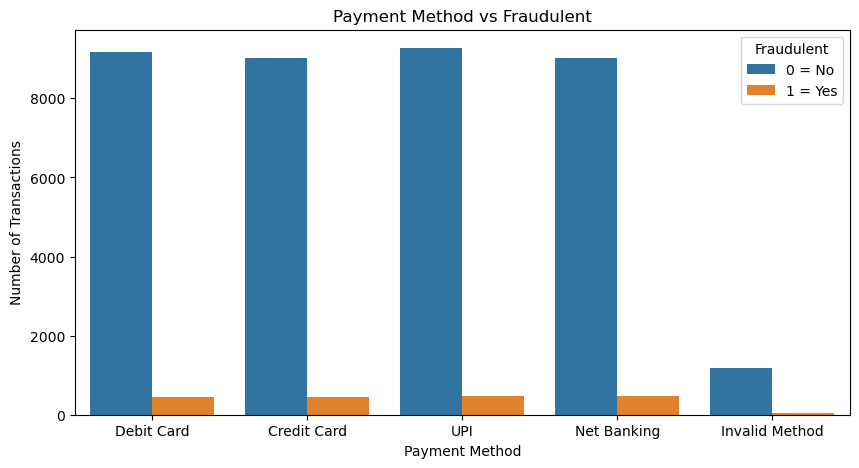

Fraudulent         0    1  Fraud_%
Payment_Method                    
Credit Card     9009  460     4.86
Debit Card      9167  456     4.74
Invalid Method  1174   56     4.55
Net Banking     9029  474     4.99
UPI             9272  486     4.98


In [11]:
plt.figure(figsize=(10, 5))

# Clustered bar chart: one group per payment method, split by fraud label
sns.countplot(x="Payment_Method", hue="Fraudulent", data=df)

plt.title("Payment Method vs Fraudulent")
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")
plt.legend(title="Fraudulent", labels=["0 = No", "1 = Yes"])

plt.show()

# Counts and fraud percentage behind the chart
task2 = pd.crosstab(df["Payment_Method"], df["Fraudulent"])
task2["Fraud_%"] = (task2[1] / task2.sum(axis=1) * 100).round(2)

print(task2)

<Axes: >

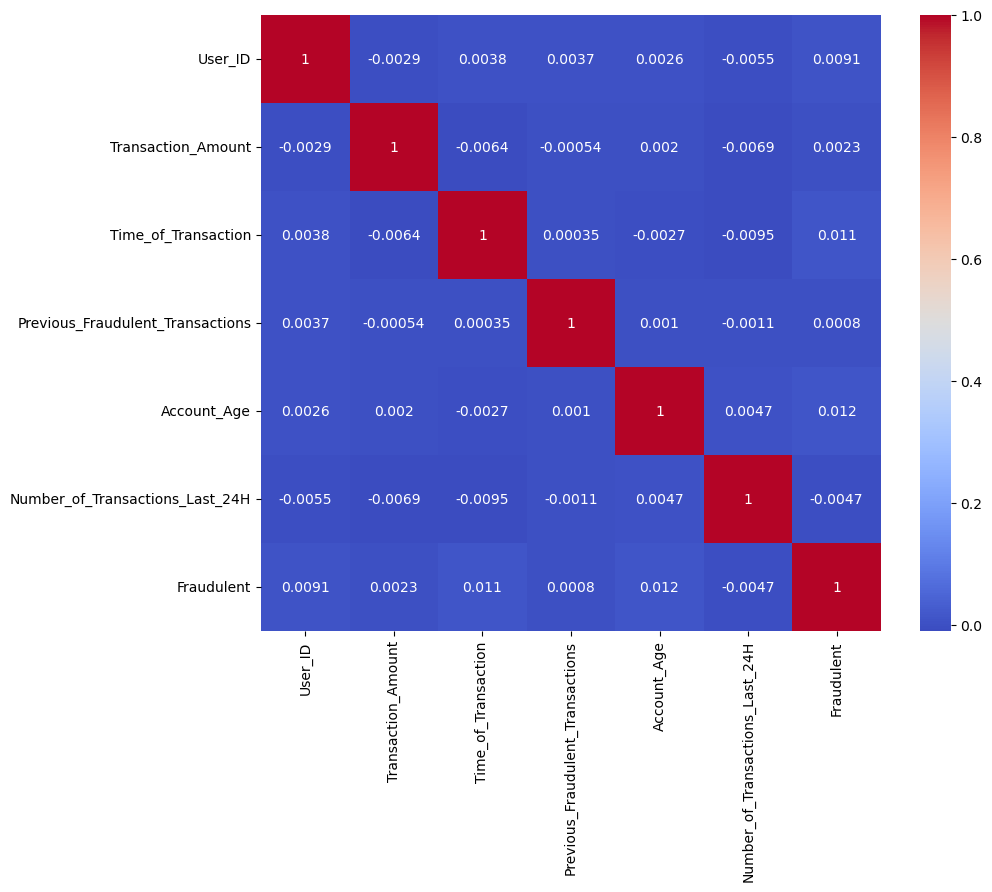

In [12]:
numeric = df.select_dtypes(include="number")

plt.figure(figsize=(10,8))

sns.heatmap(

numeric.corr(),

annot=True,

cmap="coolwarm"

)

# Outlier 

Text(0.5, 1.0, 'Transaction Amount Boxplot')

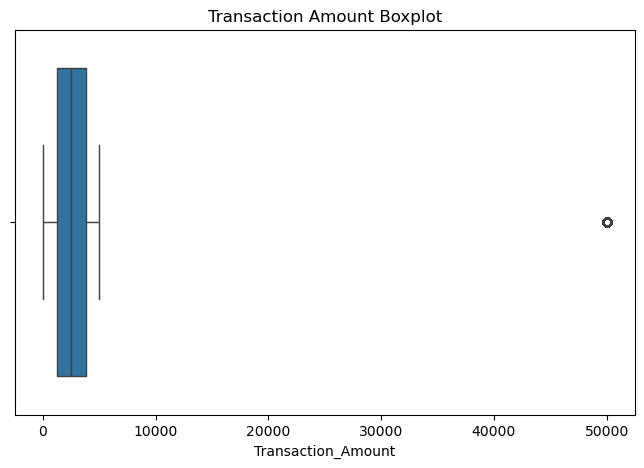

In [13]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x=df["Transaction_Amount"]
)

plt.title("Transaction Amount Boxplot")

In [14]:
Q1 = df["Transaction_Amount"].quantile(0.25)

Q3 = df["Transaction_Amount"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5*IQR

upper = Q3 + 1.5*IQR


outliers = df[
    (df["Transaction_Amount"] < lower) |
    (df["Transaction_Amount"] > upper)
]

#Lower_outlier= df[df["Transaction_Amount"] < lower]

#Lower_outlier.head()

#upper_outlier= df[df["Transaction_Amount"] < upper]

#upper_outlier.head()
#upper_outlier.shape
#Lower_outlier.shape
print(outliers.shape)
#outliers.head()

(416, 12)


## Task 2(b): Find Outlires from: Time_of_Transaction, and create graph

Q1: 5.0  Q3: 17.0  IQR: 12.0
Lower limit: -13.0  Upper limit: 35.0
Min: 0.0  Max: 23.0
Number of outliers: 0


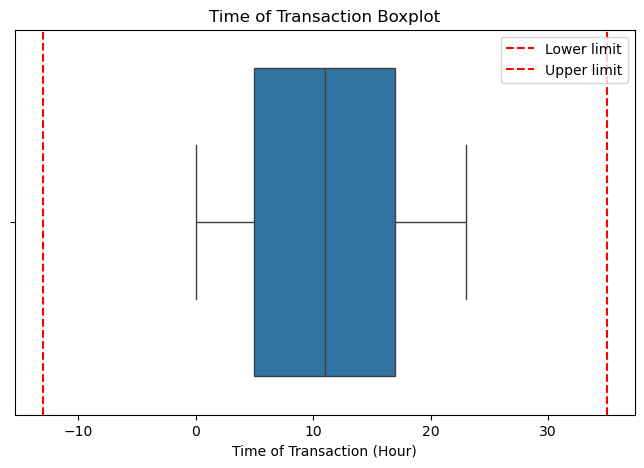

In [15]:
# IQR limits for Time_of_Transaction
Q1_t = df["Time_of_Transaction"].quantile(0.25)
Q3_t = df["Time_of_Transaction"].quantile(0.75)
IQR_t = Q3_t - Q1_t

lower_t = Q1_t - 1.5 * IQR_t
upper_t = Q3_t + 1.5 * IQR_t

# Rows outside the limits are outliers
time_outliers = df[
    (df["Time_of_Transaction"] < lower_t) |
    (df["Time_of_Transaction"] > upper_t)
]

print("Q1:", Q1_t, " Q3:", Q3_t, " IQR:", IQR_t)
print("Lower limit:", lower_t, " Upper limit:", upper_t)
print("Min:", df["Time_of_Transaction"].min(), " Max:", df["Time_of_Transaction"].max())
print("Number of outliers:", time_outliers.shape[0])

# Graph: boxplot with the outlier limits marked
plt.figure(figsize=(8, 5))

sns.boxplot(x=df["Time_of_Transaction"])

plt.axvline(lower_t, color="red", linestyle="--", label="Lower limit")
plt.axvline(upper_t, color="red", linestyle="--", label="Upper limit")

plt.title("Time of Transaction Boxplot")
plt.xlabel("Time of Transaction (Hour)")
plt.legend()

plt.show()

- Using the IQR method, the outlier limits are **-13** and **35**.
- The actual values range from **0 to 23** (hours of the day), so all values lie inside the limits.
- **Number of outliers = 0**, which the boxplot also confirms.

## Task 3: Identify Uncommon/Common Value/s

In [16]:
# Most common and least common value in each column
cols = df.columns.drop(["Transaction_ID", "Cluster"], errors="ignore")

rows = []
for col in cols:
    vc = df[col].value_counts()          # frequency of each value
    rows.append([col, vc.idxmax(), vc.max(), vc.idxmin(), vc.min()])

task3 = pd.DataFrame(
    rows,
    columns=["Column", "Most_Common", "Count", "Least_Common", "Count "]
)

print(task3.to_string(index=False))

                          Column   Most_Common  Count    Least_Common  Count 
                         User_ID          1018     23            1543       1
              Transaction_Amount       49997.8    416          394.25       1
                Transaction_Type Bank Transfer   8012 Online Purchase    7847
             Time_of_Transaction          18.0   1737            19.0    1571
                     Device_Used       Desktop  12835  Unknown Device    1237
                        Location        Boston   5045         Houston    4877
Previous_Fraudulent_Transactions             2   8083               3    7798
                     Account_Age            45    379              12     294
 Number_of_Transactions_Last_24H             5   2934               9    2693
                  Payment_Method           UPI   9758  Invalid Method    1230
                      Fraudulent             0  37651               1    1932


In [17]:
features = [
    "Transaction_Amount",
    "Previous_Fraudulent_Transactions",
    "Account_Age",
    "Number_of_Transactions_Last_24H"
]


In [18]:
from sklearn.preprocessing import StandardScaler

X = df[features]
#X=X.dropna()
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


In [19]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=0.8,
    min_samples=15
)

labels = dbscan.fit_predict(X_scaled)

In [20]:
df["Cluster"] = labels
#df.head()
df["Cluster"].value_counts()

Cluster
 0    39167
 1      408
-1        8
Name: count, dtype: int64

## Task 4: Identify Anomalies with -1 (for different feature set)

In [23]:
features_2 = ["Transaction_Amount", "Time_of_Transaction", "Account_Age"]

X2_scaled = StandardScaler().fit_transform(df[features_2])
df["Cluster_2"] = DBSCAN(eps=0.4, min_samples=15).fit_predict(X2_scaled)

print(df["Cluster_2"].value_counts())

Cluster_2
 0    39167
 1      400
-1       16
Name: count, dtype: int64


In [24]:
suspicious = df[df["Cluster"] == -1]

print(suspicious.head())

      Transaction_ID  User_ID  Transaction_Amount Transaction_Type  \
317             T318     4681             49997.8     Bill Payment   
8146           T8147     1640             49997.8     Bill Payment   
15441         T15442     4030             49997.8    Bank Transfer   
19824         T19825     2206             49997.8  Online Purchase   
22058         T22059     3612             49997.8    Bank Transfer   

       Time_of_Transaction Device_Used     Location  \
317                    0.0      Mobile      Houston   
8146                  17.0      Tablet  Los Angeles   
15441                 20.0     Desktop      Seattle   
19824                 14.0      Mobile        Miami   
22058                 20.0      Tablet     New York   

       Previous_Fraudulent_Transactions  Account_Age  \
317                                   4            4   
8146                                  4            7   
15441                                 0            5   
19824                   

## Task 5(a): Create Graphs for Anomalies

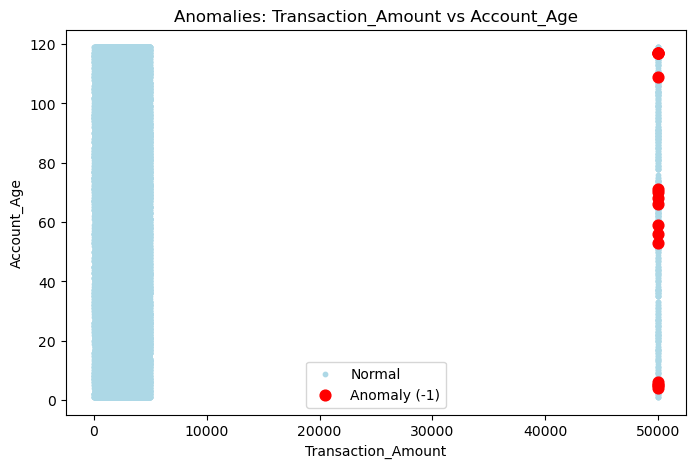

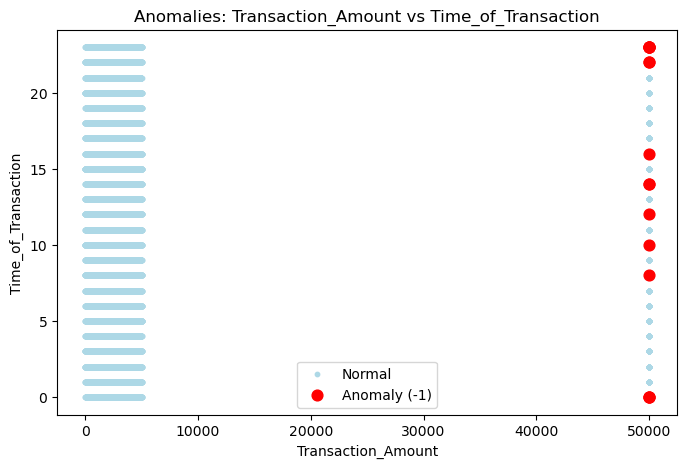

In [25]:
normal = df[df["Cluster_2"] != -1]
anomaly = df[df["Cluster_2"] == -1]

# Two graphs: amount vs account age, and amount vs time
for y_col in ["Account_Age", "Time_of_Transaction"]:
    plt.figure(figsize=(8, 5))

    plt.scatter(normal["Transaction_Amount"], normal[y_col],
                c="lightblue", s=10, label="Normal")
    plt.scatter(anomaly["Transaction_Amount"], anomaly[y_col],
                c="red", s=60, label="Anomaly (-1)")

    plt.xlabel("Transaction_Amount")
    plt.ylabel(y_col)
    plt.title("Anomalies: Transaction_Amount vs " + y_col)
    plt.legend()
    plt.show()

## Task 5(b): Cluster Graph (any two attributes)

In [26]:
x_attr = "Transaction_Amount"   
y_attr = "Previous_Fraudulent_Transactions"          


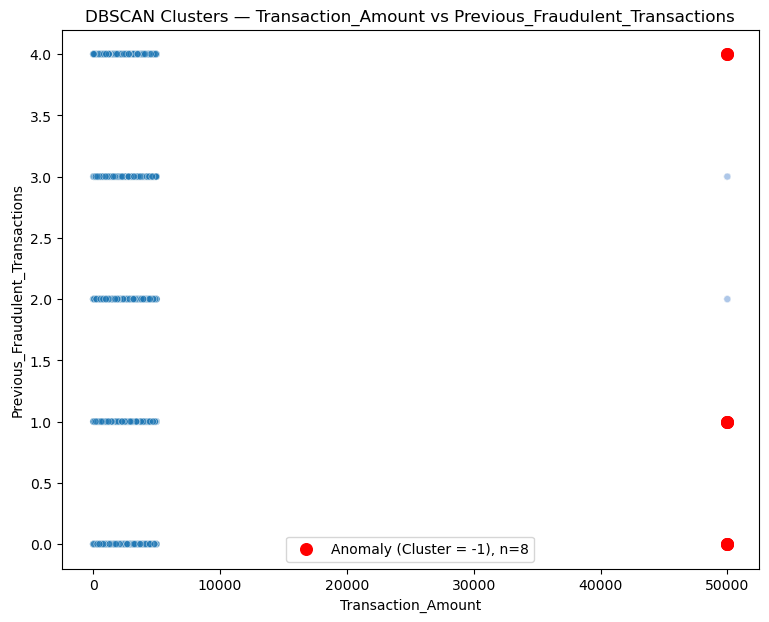

In [27]:
non_noise = df[df["Cluster"] != -1]
noise = df[df["Cluster"] == -1]

sample_size = min(3000, len(non_noise))
plot_sample = non_noise.sample(n=sample_size, random_state=42)

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=plot_sample,
    x=x_attr, y=y_attr,
    hue="Cluster",
    palette="tab20",
    alpha=0.6, s=25,
    legend=False
)

plt.scatter(
    noise[x_attr], noise[y_attr],
    c="red", marker="o", s=70,
    label=f"Anomaly (Cluster = -1), n={len(noise)}"
)

plt.xlabel(x_attr)
plt.ylabel(y_attr)
plt.title(f"DBSCAN Clusters — {x_attr} vs {y_attr}")
plt.legend()
plt.show()
